# Rolimons and Rotrends in the Consistent panel

Daily, from 2024-01 onwards (Rotrends from 2024-09-05).

1. **Coverage:** distinct games each source returns per day.
2. **Rotrends 5k+:** Rotrends games with an estimated daily average of 5k or more, and how many of those were in neither the scan nor Rolimons that day (the games the Consistent panel actually adds from Rotrends).
3. **Consistent panel by source:** the games and daily average CCU in the Consistent panel (`player_trend`, datasource `'Consistent'`), split into the SRS scan, the scan-gap fill, the Rolimons gap-fill and the Rotrends gap-fill.

**Rotrends, Consistent methodology** throughout means `bots.rblx.rotrend_games_adj`:
- topgames history up to 2026-06-09, then the list feed (list wins on overlapping days); the list backfill bundle is excluded upstream
- `players_avg_est` (estimated daily average) as the player count
- `player_trend`'s exclusions: 2024-10-16 to 10-21 (bad data) and dates after the latest SRS scrape

**Shaded days (Rotrends):** the list readings for 2026-06-10 to 06-22 and 06-26 were not taken at ~00:00 UTC, which the scaling assumes. They were at about 02:00 UTC for 06-10 to 06-18 and 06-21, about 14:00 the previous day for 06-19, about 12:00 for 06-20, about 06:00 for 06-22, and 06-26 is a stale copy of 06-25. The estimates on those days are off by up to ±30%. They are shown as the Consistent panel uses them today.

In [1]:
import os
from datetime import datetime, timedelta

import matplotlib.pyplot as plt
import pandas as pd
import snowflake.connector

CCU_THRESHOLD = 5000
START = "2024-01-01"
# Rotrends list days whose reading was not at ~00:00 UTC (see above).
MISTIMED_LIST_DAYS = [("2026-06-10", "2026-06-22"), ("2026-06-26", "2026-06-26")]

conn = snowflake.connector.connect(
    connection_name=os.getenv("SNOWFLAKE_CONNECTION", "default"),
)


def q(sql: str) -> pd.DataFrame:
    df = conn.cursor().execute(sql).fetch_pandas_all()
    df.columns = [c.lower() for c in df.columns]
    for c in df:
        if c == "date":
            df[c] = pd.to_datetime(df[c])
        elif df[c].dtype == object and c != "source":
            df[c] = df[c].astype(float)  # Snowflake NUMBER arrives as Decimal
    return df


def shade_mistimed(ax):
    for i, (a, b) in enumerate(MISTIMED_LIST_DAYS):
        start = datetime.fromisoformat(a)
        end = datetime.fromisoformat(b) + timedelta(days=1)
        ax.axvspan(start, end, color="red", alpha=0.12, lw=0, label="mis-timed list readings" if i == 0 else None)


def daily(s: pd.Series) -> pd.Series:
    """Reindex to every calendar day so missing days show as gaps."""
    return s.asfreq("D")


# Rotrends rows as the Consistent panel sees them.
ROTRENDS_CONSISTENT = f"""
    SELECT game_id, date, players_avg_est, is_missing
    FROM bots.rblx.rotrend_games_adj
    WHERE date >= '{START}'
        AND date NOT BETWEEN '2024-10-16' AND '2024-10-21'
        AND date <= (SELECT MAX(rundate :: DATE) FROM bots.rblx.game_rank)
"""

## 1. Coverage: distinct games per day

Every game each source returns, with no CCU threshold. Rolimons counts distinct places with any reading that day (`rolimons_game`); its final day is dropped because the latest dump ends partway through it.

In [2]:
coverage = q(f"""
    SELECT 'Rolimons' AS source, runtime :: DATE AS date, COUNT(DISTINCT place_id) AS games
    FROM bots.rblx.rolimons_game
    WHERE runtime >= '{START}'
        AND runtime :: DATE < (SELECT MAX(runtime :: DATE) FROM bots.rblx.rolimons_game)
    GROUP BY 1, 2
    UNION ALL
    SELECT 'Rotrends', date, COUNT(DISTINCT game_id)
    FROM ({ROTRENDS_CONSISTENT})
    GROUP BY 1, 2
""").pivot(index="date", columns="source", values="games").sort_index()

coverage.resample("QS").mean().round(0)

source,Rolimons,Rotrends
date,,
2024-01-01,2357.0,NaN
2024-04-01,2616.0,NaN
2024-07-01,2877.0,1965.0
2024-10-01,3172.0,2060.0
2025-01-01,3441.0,2477.0
2025-04-01,3865.0,3090.0
2025-07-01,4450.0,3849.0
2025-10-01,4906.0,4548.0
2026-01-01,5476.0,5533.0


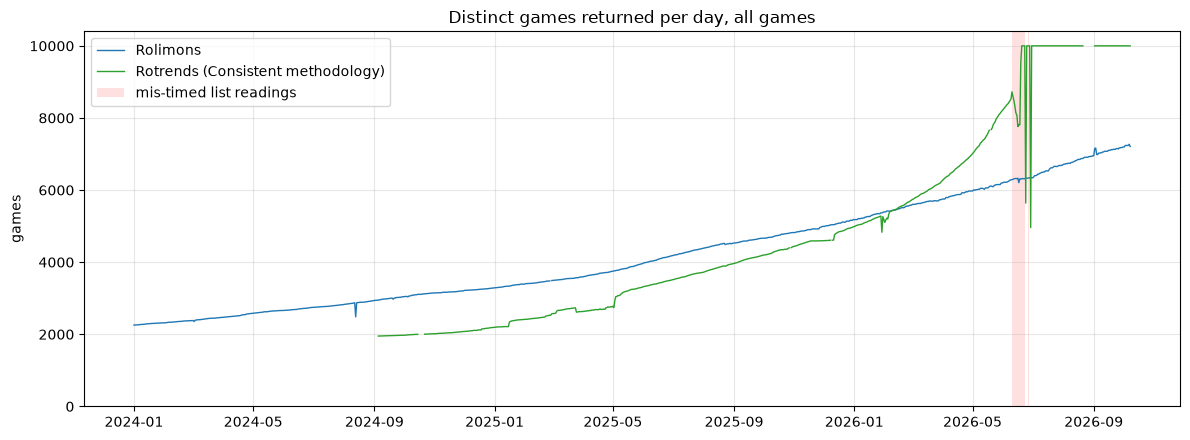

In [3]:
fig, ax = plt.subplots(figsize=(12, 4.5))
for source, color in [("Rolimons", "tab:blue"), ("Rotrends", "tab:green")]:
    s = daily(coverage[source].dropna())
    ax.plot(s.index, s.values, lw=1, color=color, label=source + (" (Consistent methodology)" if source == "Rotrends" else ""))
shade_mistimed(ax)
ax.set_title("Distinct games returned per day, all games")
ax.set_ylabel("games")
ax.set_ylim(bottom=0)
ax.grid(alpha=0.3)
ax.legend(loc="upper left")
plt.tight_layout()

## 2. Rotrends games at 5k+ estimated daily average

- **5k+:** Rotrends games with `players_avg_est` of 5k or more that day. These are the games eligible for Consistent's Rotrends gap-fill.
- **5k+ and in neither scan nor Rolimons:** the subset with `is_missing`, i.e. not in the SRS scan (`game_rank`) or the Rolimons gap-fill (`rolimons_game_adj`) that day. These are the games the Consistent panel adds from Rotrends.

The red spikes on **2025-04-15 (140 games)** and **2025-06-27 (211)** are days with no SRS scan at all, so every Rotrends game counts as missing. `player_trend` attaches the gap-fill to that day's scan snapshots, so on a day with no scan none of these games reach the panel (see chart 3).

In [4]:
rotrends_5k = q(f"""
    SELECT
        date,
        COUNT(DISTINCT IFF(players_avg_est >= {CCU_THRESHOLD}, game_id, NULL)) AS games_5k,
        COUNT(DISTINCT IFF(players_avg_est >= {CCU_THRESHOLD} AND is_missing, game_id, NULL)) AS games_5k_missing
    FROM ({ROTRENDS_CONSISTENT})
    GROUP BY 1
    ORDER BY 1
""").set_index("date")

rotrends_5k.resample("QS").mean().round(1)

,games_5k,games_5k_missing
date,,
2024-07-01,129.3,0.0
2024-10-01,131.0,0.1
2025-01-01,154.5,3.7
2025-04-01,174.6,6.0
2025-07-01,219.9,2.7
2025-10-01,225.6,2.2
2026-01-01,241.5,2.1
2026-04-01,264.6,2.8
2026-07-01,289.2,4.9


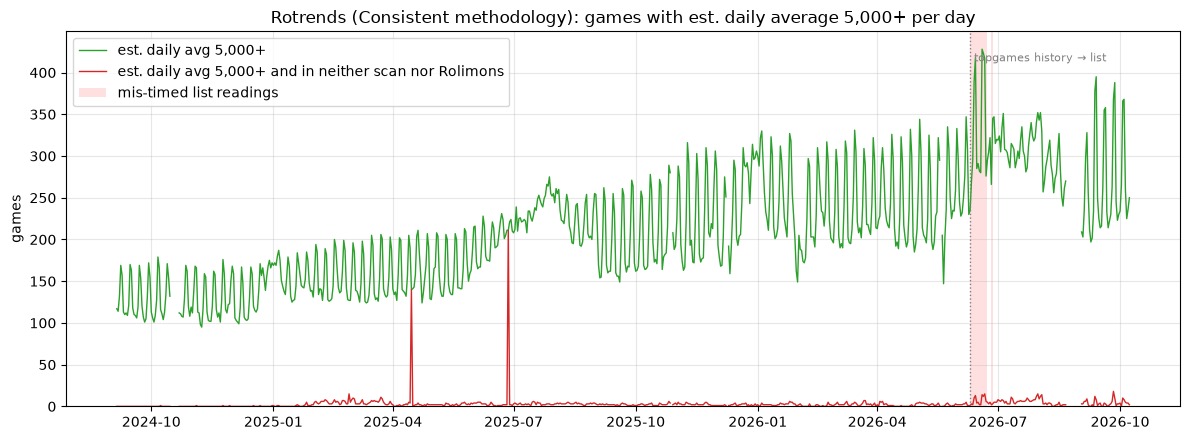

In [5]:
fig, ax = plt.subplots(figsize=(12, 4.5))
s = daily(rotrends_5k["games_5k"])
ax.plot(s.index, s.values, lw=1, color="tab:green", label=f"est. daily avg {CCU_THRESHOLD:,}+")
s = daily(rotrends_5k["games_5k_missing"])
ax.plot(s.index, s.values, lw=1, color="tab:red", label=f"est. daily avg {CCU_THRESHOLD:,}+ and in neither scan nor Rolimons")
shade_mistimed(ax)
ax.axvline(pd.Timestamp("2026-06-10"), color="grey", ls=":", lw=1)
ax.text(pd.Timestamp("2026-06-10"), ax.get_ylim()[1] * 0.92, " topgames history → list", fontsize=8, color="grey")
ax.set_title(f"Rotrends (Consistent methodology): games with est. daily average {CCU_THRESHOLD:,}+ per day")
ax.set_ylabel("games")
ax.set_ylim(bottom=0)
ax.grid(alpha=0.3)
ax.legend(loc="upper left")
plt.tight_layout()

## 3. Consistent panel by source

Rebuilt from the source tables the way `player_trend.sql` builds it (one reading per game and snapshot, summed by UTC hour, averaged over the day's hours):
- **SRS scan:** `game_rank` scanned rows.
- **Scan-gap fill:** readings for snapshots a scanned game is missing from (Rolimons within ±5 min, else the game's own SRS average). It is `player_trend`'s `'SRS'` series minus the scan. These games are already in the scan that day, so it adds CCU but no games.
- **Rolimons gap-fill:** `rolimons_game_adj WHERE is_missing` (any size).
- **Rotrends gap-fill:** `rotrend_games_adj WHERE is_missing` with est. daily average 5k+.

The **check** column is `player_trend`'s Consistent daily average CCU minus the sum of the four parts. It should be 0.

In [6]:
consistent = q(f"""
    WITH pt AS (
        SELECT date, datasource, COUNT(*) AS hours, SUM(players) AS players_sum
        FROM bots.rblx.player_trend
        WHERE datasource IN ('Consistent', 'SRS')
            AND date >= '{START}'
        GROUP BY 1, 2
    ),
    scan AS (
        SELECT rundate :: DATE AS date, COUNT(DISTINCT universe_id) AS games, SUM(players) AS players_sum
        FROM (
            SELECT universe_id, rundate, MAX(players) AS players
            FROM bots.rblx.game_rank
            WHERE universe_id > 0
                AND file_name ILIKE '%scan%'
                AND rundate >= '{START}'
            GROUP BY 1, 2
        )
        GROUP BY 1
    ),
    rolimons_fill AS (
        -- Unmapped places (NULL universe_id) drop out of player_trend's join, so here too.
        SELECT rundate :: DATE AS date, COUNT(DISTINCT universe_id) AS games, SUM(players) AS players_sum
        FROM (
            SELECT universe_id, rundate, MAX(players) AS players
            FROM bots.rblx.rolimons_game_adj
            WHERE is_missing
                AND universe_id IS NOT NULL
                AND rundate >= '{START}'
            GROUP BY 1, 2
        )
        GROUP BY 1
    ),
    snapshots AS (
        SELECT DISTINCT rundate, rundate :: DATE AS date
        FROM bots.rblx.game_rank
        WHERE universe_id > 0
            AND file_name ILIKE '%scan%'
            AND rundate >= '{START}'
    ),
    rotrends_fill AS (
        -- player_trend copies each daily estimate into every scan snapshot of the day.
        SELECT r.date, COUNT(DISTINCT r.game_id) AS games, SUM(r.players_avg_est) AS players_sum
        FROM ({ROTRENDS_CONSISTENT}) r
        JOIN snapshots s
            ON s.date = r.date
        WHERE r.is_missing
            AND r.players_avg_est >= {CCU_THRESHOLD}
        GROUP BY 1
    )
    SELECT
        c.date,
        sc.games AS games_scan,
        COALESCE(rl.games, 0) AS games_rolimons_fill,
        COALESCE(rt.games, 0) AS games_rotrends_fill,
        sc.players_sum / c.hours AS ccu_scan,
        (srs.players_sum - sc.players_sum) / c.hours AS ccu_scan_gap_fill,
        COALESCE(rl.players_sum, 0) / c.hours AS ccu_rolimons_fill,
        COALESCE(rt.players_sum, 0) / c.hours AS ccu_rotrends_fill,
        c.players_sum / c.hours AS ccu_consistent
    FROM pt c
    JOIN pt srs
        ON srs.date = c.date
        AND srs.datasource = 'SRS'
    LEFT JOIN scan sc
        ON sc.date = c.date
    LEFT JOIN rolimons_fill rl
        ON rl.date = c.date
    LEFT JOIN rotrends_fill rt
        ON rt.date = c.date
    WHERE c.datasource = 'Consistent'
    ORDER BY 1
""").set_index("date")

CCU_PARTS = ["ccu_scan", "ccu_scan_gap_fill", "ccu_rolimons_fill", "ccu_rotrends_fill"]
consistent["check"] = consistent["ccu_consistent"] - consistent[CCU_PARTS].sum(axis=1)
print(f"max |check|: {consistent['check'].abs().max():,.1f} CCU")

summary = consistent.resample("QS").mean()
for part in CCU_PARTS:
    summary[part.replace("ccu_", "share_")] = summary[part] / summary["ccu_consistent"]
summary.drop(columns="check").style.format("{:,.0f}").format("{:.2%}", subset=[c for c in summary if c.startswith("share_")])

max |check|: 0.0 CCU


,games_scan,games_rolimons_fill,games_rotrends_fill,ccu_scan,ccu_scan_gap_fill,ccu_rolimons_fill,ccu_rotrends_fill,ccu_consistent,share_scan,share_scan_gap_fill,share_rolimons_fill,share_rotrends_fill
date,,,,,,,,,,,,
2024-01-01 00:00:00,"10,025",109,0,"5,524,450","10,910","34,685",0,"5,570,046",99.18%,0.20%,0.62%,0.00%
2024-04-01 00:00:00,"10,049",147,0,"5,873,979","10,816","14,505",0,"5,899,299",99.57%,0.18%,0.25%,0.00%
2024-07-01 00:00:00,"10,024",210,0,"6,832,852","7,539","28,314",0,"6,868,705",99.48%,0.11%,0.41%,0.00%
2024-10-01 00:00:00,"10,107",310,0,"6,012,781","25,169","89,432",551,"6,127,933",98.12%,0.41%,1.46%,0.01%
2025-01-01 00:00:00,"10,178",467,4,"6,426,890","5,632","507,553","32,211","6,972,287",92.18%,0.08%,7.28%,0.46%
2025-04-01 00:00:00,"11,407",411,2,"9,129,091","17,203","204,903","15,886","9,367,082",97.46%,0.18%,2.19%,0.17%
2025-07-01 00:00:00,"11,700",579,3,"13,007,766","42,235","285,196","17,944","13,353,140",97.41%,0.32%,2.14%,0.13%
2025-10-01 00:00:00,"11,737",732,2,"11,791,387","27,361","159,233","14,837","11,992,818",98.32%,0.23%,1.33%,0.12%
2026-01-01 00:00:00,"11,852",848,2,"10,605,655","27,909","158,053","18,728","10,810,345",98.11%,0.26%,1.46%,0.17%


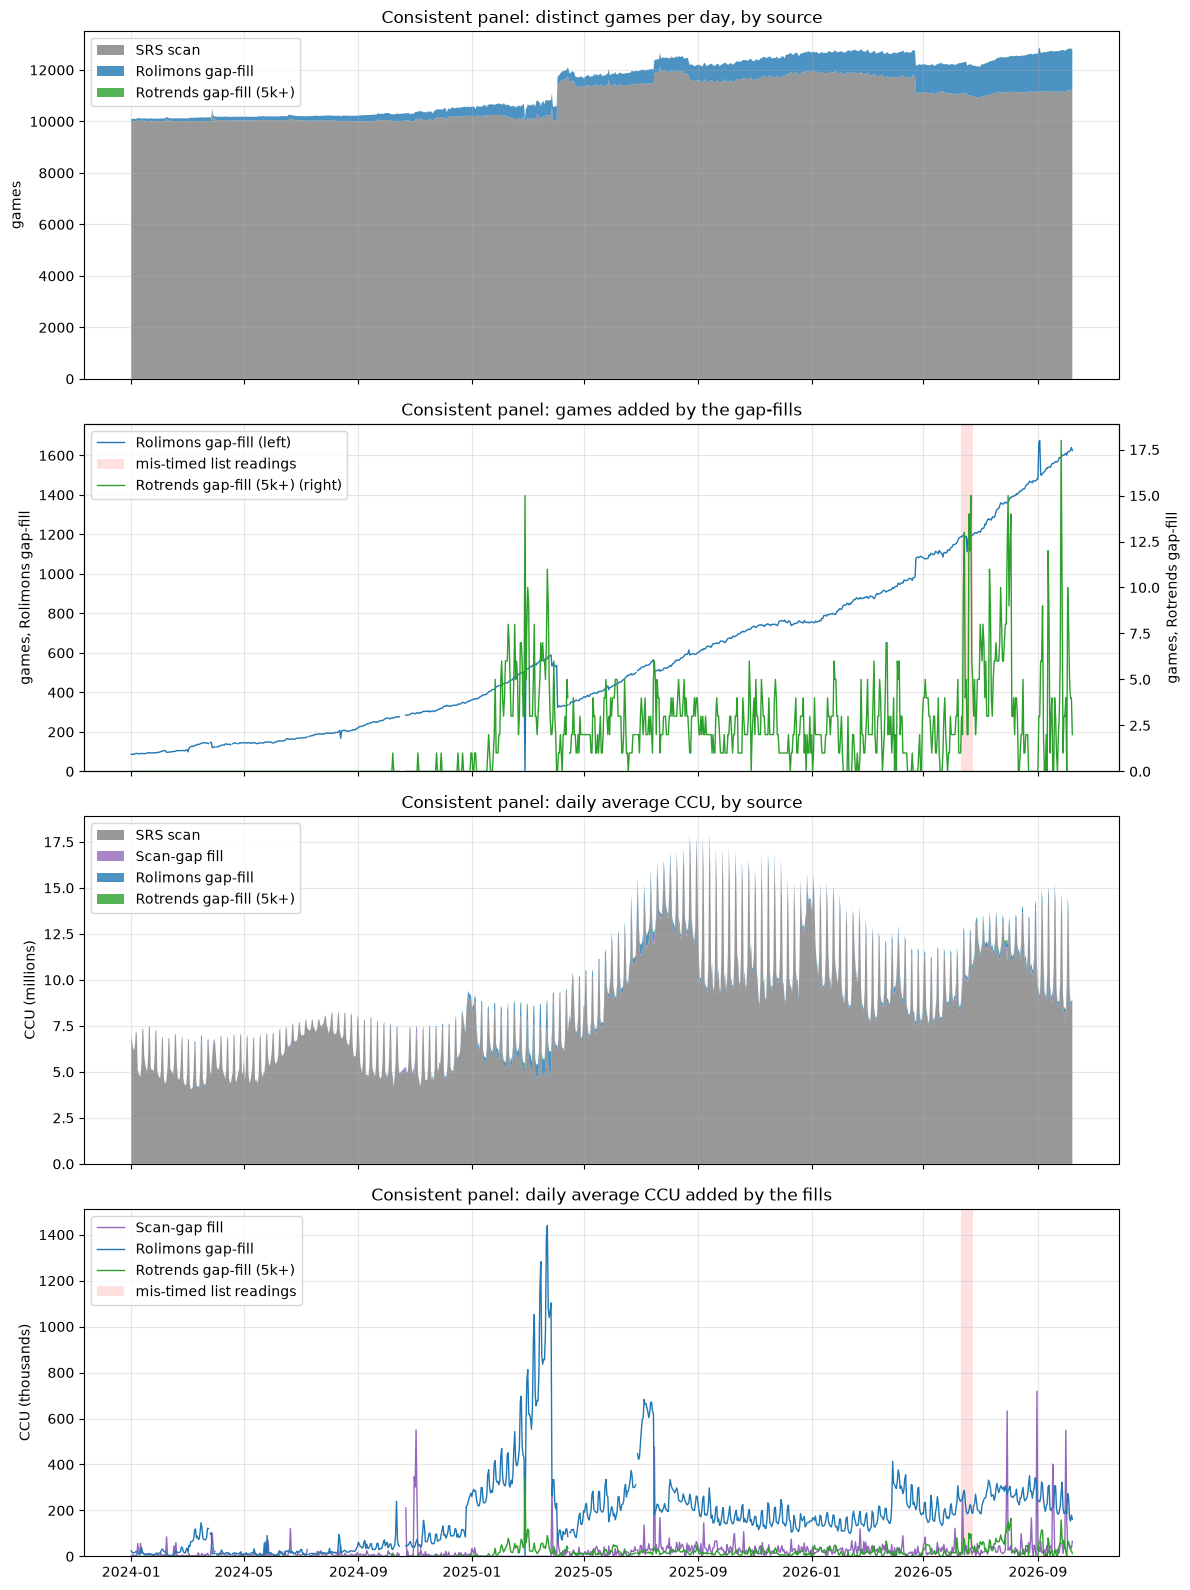

In [7]:
COLORS = {"scan": "tab:grey", "scan_gap_fill": "tab:purple", "rolimons_fill": "tab:blue", "rotrends_fill": "tab:green"}
LABELS = {"scan": "SRS scan", "scan_gap_fill": "Scan-gap fill", "rolimons_fill": "Rolimons gap-fill", "rotrends_fill": "Rotrends gap-fill (5k+)"}
d = consistent  # stacked charts: days with no data are skipped rather than drawn as zero
dd = consistent.asfreq("D")  # line charts: missing days show as gaps

fig, axes = plt.subplots(4, 1, figsize=(12, 16), sharex=True)

ax = axes[0]
keys = ["scan", "rolimons_fill", "rotrends_fill"]
ax.stackplot(d.index, [d[f"games_{k}"] for k in keys],
             labels=[LABELS[k] for k in keys], colors=[COLORS[k] for k in keys], alpha=0.8)
ax.set_title("Consistent panel: distinct games per day, by source")
ax.set_ylabel("games")
ax.legend(loc="upper left")

ax = axes[1]
ax.plot(dd.index, dd["games_rolimons_fill"], lw=1, color=COLORS["rolimons_fill"], label=LABELS["rolimons_fill"] + " (left)")
ax.set_ylabel("games, Rolimons gap-fill")
ax2 = ax.twinx()
ax2.plot(dd.index, dd["games_rotrends_fill"], lw=1, color=COLORS["rotrends_fill"], label=LABELS["rotrends_fill"] + " (right)")
ax2.set_ylabel("games, Rotrends gap-fill")
ax2.set_ylim(bottom=0)
shade_mistimed(ax)
ax.set_title("Consistent panel: games added by the gap-fills")
handles = ax.get_legend_handles_labels()
handles2 = ax2.get_legend_handles_labels()
ax.legend(handles[0] + handles2[0], handles[1] + handles2[1], loc="upper left")

ax = axes[2]
keys = ["scan", "scan_gap_fill", "rolimons_fill", "rotrends_fill"]
ax.stackplot(d.index, [d[f"ccu_{k}"] / 1e6 for k in keys],
             labels=[LABELS[k] for k in keys], colors=[COLORS[k] for k in keys], alpha=0.8)
ax.set_title("Consistent panel: daily average CCU, by source")
ax.set_ylabel("CCU (millions)")
ax.legend(loc="upper left")

ax = axes[3]
for k in ["scan_gap_fill", "rolimons_fill", "rotrends_fill"]:
    ax.plot(dd.index, dd[f"ccu_{k}"] / 1e3, lw=1, color=COLORS[k], label=LABELS[k])
shade_mistimed(ax)
ax.set_title("Consistent panel: daily average CCU added by the fills")
ax.set_ylabel("CCU (thousands)")
ax.legend(loc="upper left")

for ax in axes:
    ax.set_ylim(bottom=0)
    ax.grid(alpha=0.3)
plt.tight_layout()

## 4. 5k+ games each source has, and how many it actually adds

7-day trailing average of the daily count of distinct games with a **daily average CCU of 5k+**.

- **Rolimons**
  - *5k+ in Rolimons:* the game's average Rolimons reading that day (`rolimons_game_universe`) is 5k or more. Its last day is dropped, because the latest dump ends partway through it.
  - *Added to Consistent:* the subset that went into the Rolimons gap-fill that day (`rolimons_game_adj WHERE is_missing`), i.e. not in the SRS scan that day. The threshold uses the raw Rolimons average for both lines, so the second is a strict subset. The panel itself uses the rescaled value, which is about 1% different.
- **Rotrends** (Consistent methodology)
  - *5k+ in Rotrends:* `players_avg_est` of 5k or more (as in chart 2).
  - *Added to Consistent:* the subset in neither the SRS scan nor Rolimons that day (`is_missing`), counted only on days with a scan, since the panel attaches the gap-fill to scan snapshots. This is the number of 5k+ games Rotrends adds on top of the scan and Rolimons.

The trailing average needs at least 5 of the 7 days to have data, so the Rotrends gap (2026-08-22 to 09-01) and excluded dates show as breaks.

In [8]:
rolimons_5k = q(f"""
    WITH daily AS (
        -- Unmapped places keep their own key so they still count in the first line.
        SELECT COALESCE(universe_id, -place_id) AS game_key, universe_id, runtime :: DATE AS date, AVG(players) AS avg_ccu
        FROM bots.rblx.rolimons_game_universe
        WHERE runtime >= '{START}'
            AND runtime :: DATE < (SELECT MAX(runtime :: DATE) FROM bots.rblx.rolimons_game_universe)
        GROUP BY 1, 2, 3
    ),
    added AS (
        SELECT DISTINCT universe_id, rundate :: DATE AS date
        FROM bots.rblx.rolimons_game_adj
        WHERE is_missing
            AND universe_id IS NOT NULL
            AND rundate >= '{START}'
    )
    SELECT
        d.date,
        COUNT(DISTINCT IFF(d.avg_ccu >= {CCU_THRESHOLD}, d.game_key, NULL)) AS games_5k,
        COUNT(DISTINCT IFF(d.avg_ccu >= {CCU_THRESHOLD} AND a.universe_id IS NOT NULL, d.game_key, NULL)) AS games_5k_added
    FROM daily d
    LEFT JOIN added a
        ON a.universe_id = d.universe_id
        AND a.date = d.date
    GROUP BY 1
    ORDER BY 1
""").set_index("date")

rotrends_5k_added = q(f"""
    WITH scan_days AS (
        SELECT DISTINCT rundate :: DATE AS date
        FROM bots.rblx.game_rank
        WHERE universe_id > 0
            AND file_name ILIKE '%scan%'
            AND rundate >= '{START}'
    )
    SELECT
        r.date,
        COUNT(DISTINCT IFF(r.players_avg_est >= {CCU_THRESHOLD}, r.game_id, NULL)) AS games_5k,
        COUNT(DISTINCT IFF(r.players_avg_est >= {CCU_THRESHOLD} AND r.is_missing AND s.date IS NOT NULL, r.game_id, NULL)) AS games_5k_added
    FROM ({ROTRENDS_CONSISTENT}) r
    LEFT JOIN scan_days s
        ON s.date = r.date
    GROUP BY 1
    ORDER BY 1
""").set_index("date")


def trailing_7d(df: pd.DataFrame) -> pd.DataFrame:
    return df.asfreq("D").rolling(7, min_periods=5).mean()


rolimons_5k_7d = trailing_7d(rolimons_5k)
rotrends_5k_7d = trailing_7d(rotrends_5k_added)

pd.concat(
    {"rolimons": rolimons_5k.resample("QS").mean(), "rotrends": rotrends_5k_added.resample("QS").mean()}, axis=1
).round(1)

rolimons                rotrends               
           games_5k games_5k_added games_5k games_5k_added
date                                                      
2024-01-01    131.1            1.2      NaN            NaN
2024-04-01    136.5            0.2      NaN            NaN
2024-07-01    152.9            0.5    129.3            0.0
2024-10-01    132.7            1.6    131.0            0.1
2025-01-01    152.8           11.9    154.5            3.7
2025-04-01    179.1            7.0    174.6            2.1
2025-07-01    218.9            7.1    219.9            2.7
2025-10-01    205.3            3.6    225.6            2.2
2026-01-01    221.9            2.5    241.5            2.1
2026-04-01    232.7            5.0    264.6            2.8
2026-07-01    277.8            5.6    289.2            4.9
2026-10-01    246.1            1.4    275.5            4.6

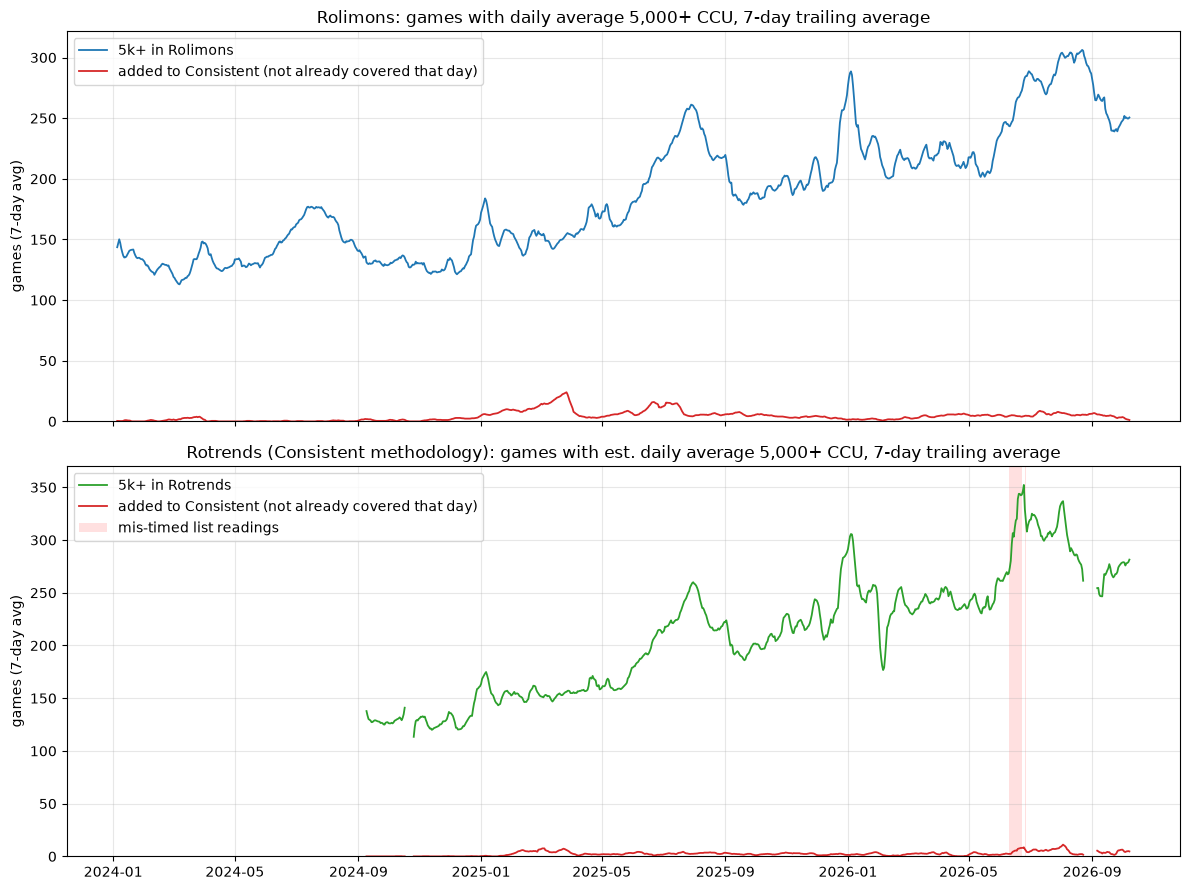

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(12, 9), sharex=True)

for ax, df, source, color in [
    (axes[0], rolimons_5k_7d, "Rolimons", "tab:blue"),
    (axes[1], rotrends_5k_7d, "Rotrends", "tab:green"),
]:
    ax.plot(df.index, df["games_5k"], lw=1.3, color=color, label=f"5k+ in {source}")
    ax.plot(df.index, df["games_5k_added"], lw=1.3, color="tab:red", label="added to Consistent (not already covered that day)")
    ax.set_ylabel("games (7-day avg)")
    ax.set_ylim(bottom=0)
    ax.grid(alpha=0.3)

axes[0].set_title(f"Rolimons: games with daily average {CCU_THRESHOLD:,}+ CCU, 7-day trailing average")
axes[1].set_title(f"Rotrends (Consistent methodology): games with est. daily average {CCU_THRESHOLD:,}+ CCU, 7-day trailing average")
shade_mistimed(axes[1])
for ax in axes:
    ax.legend(loc="upper left")
plt.tight_layout()

## 5. New games per day, and how soon after creation each source picks them up

For each source, a game is **new** on the day it first appears in that source. Each chart shows:
- **Left axis:** the 7-day trailing average of new games per day.
- **Right axis:** the share of the new games over the same trailing 7 days that first appeared within **30 / 60 / 90 days** of their Roblox creation date.

Definitions:
- **Creation date (as "publication"):** there is no publication date in our data. The closest is the universe's Roblox creation date, taken as the earliest across `game_meta_v3.created_at`, `game_meta_v2.create_date`, `rotrend_list.created` and `rotrend_topgames.created` (these agree to within a day for over 99.9% of games; junk dates before 2006 are ignored). A game can be created privately and made public later, so the shares understate how quickly the sources pick up games after they actually go live.
- **Rolimons first appearance:** the game's first reading in `rolimons_game_universe` (full history back to 2019). About 3% of Rolimons games have no creation date (mostly unmapped places) and are left out.
- **Rotrends first appearance:** the game's first date under the Consistent methodology (`rotrend_games_adj`: topgames history, then list), **all games, with no CCU threshold**.
  - Topgames history starts on 2024-09-05 for every game, so the chart starts at 2024-10-01.
  - Topgames history only holds games still on the list in June 2026, so earlier first appearances cover only those games.
  - When the list replaced topgames (2026-06-10) and grew to 10,000 games (06-19), thousands of older games appear for the first time at once.
- Days a source has no data (e.g. the Rotrends gap from 2026-08-22 to 09-01) are blank rather than zero; the trailing window needs at least 5 days with data.

In [10]:
ROTRENDS_FIRST_USABLE = "2024-10-01"  # topgames history starts 2024-09-05 for every game
LAG_BUCKETS = [30, 60, 90]

first_seen = q(f"""
    WITH created AS (
        SELECT universe_id, MIN(created) :: DATE AS created
        FROM (
            SELECT universe_id, created_at AS created FROM bots.rblx.game_meta_v3 WHERE universe_id > 0
            UNION ALL
            SELECT universe_id, create_date FROM bots.rblx.game_meta_v2 WHERE universe_id > 0
            UNION ALL
            SELECT game_id, created FROM bots.rblx.rotrend_list
            UNION ALL
            SELECT game_id, created FROM bots.rblx.rotrend_topgames
        )
        -- A few feeds carry junk dates (year 0); Roblox launched in 2006.
        WHERE created >= '2006-01-01'
        GROUP BY 1
    ),
    firsts AS (
        SELECT 'Rolimons' AS source, universe_id, MIN(runtime) :: DATE AS first_seen
        FROM bots.rblx.rolimons_game_universe
        WHERE universe_id IS NOT NULL
        GROUP BY 1, 2
        UNION ALL
        SELECT 'Rotrends', game_id, MIN(date)
        FROM ({ROTRENDS_CONSISTENT})
        GROUP BY 1, 2
    )
    SELECT f.source, f.universe_id, f.first_seen AS date,
        GREATEST(DATEDIFF(day, c.created, f.first_seen), 0) AS lag_days
    FROM firsts f
    JOIN created c
        ON c.universe_id = f.universe_id
    WHERE f.first_seen >= IFF(f.source = 'Rotrends', '{ROTRENDS_FIRST_USABLE}', '{START}')
""")


def new_games_7d(games: pd.DataFrame, data_days: pd.DatetimeIndex) -> pd.DataFrame:
    """Trailing-7-day average of new games per day, and the share within each lag bucket."""
    daily = games.groupby("date").agg(
        new_games=("lag_days", "size"),
        **{f"within_{n}d": ("lag_days", lambda s, n=n: (s <= n).sum()) for n in LAG_BUCKETS},
    ).astype(float)
    days = pd.date_range(games["date"].min(), games["date"].max(), freq="D")
    daily = daily.reindex(days, fill_value=0.0)
    daily[~daily.index.isin(data_days)] = None  # no data that day, not zero new games
    sums = daily.rolling(7, min_periods=5).sum()
    out = pd.DataFrame({"new_games_7d_avg": daily["new_games"].rolling(7, min_periods=5).mean()})
    for n in LAG_BUCKETS:
        out[f"pct_within_{n}d"] = sums[f"within_{n}d"] / sums["new_games"]
    return out


new_games = {
    source: new_games_7d(g, coverage[source].dropna().index)
    for source, g in first_seen.groupby("source")
}

quarterly = (
    first_seen.assign(**{f"pct_within_{n}d": first_seen["lag_days"] <= n for n in LAG_BUCKETS})
    .groupby(["source", pd.Grouper(key="date", freq="QS")])
    .agg(new_games=("lag_days", "size"), **{f"pct_within_{n}d": (f"pct_within_{n}d", "mean") for n in LAG_BUCKETS})
    .unstack(0)
)
quarterly.style.format("{:.0%}", na_rep="").format("{:,.0f}", subset=["new_games"], na_rep="")

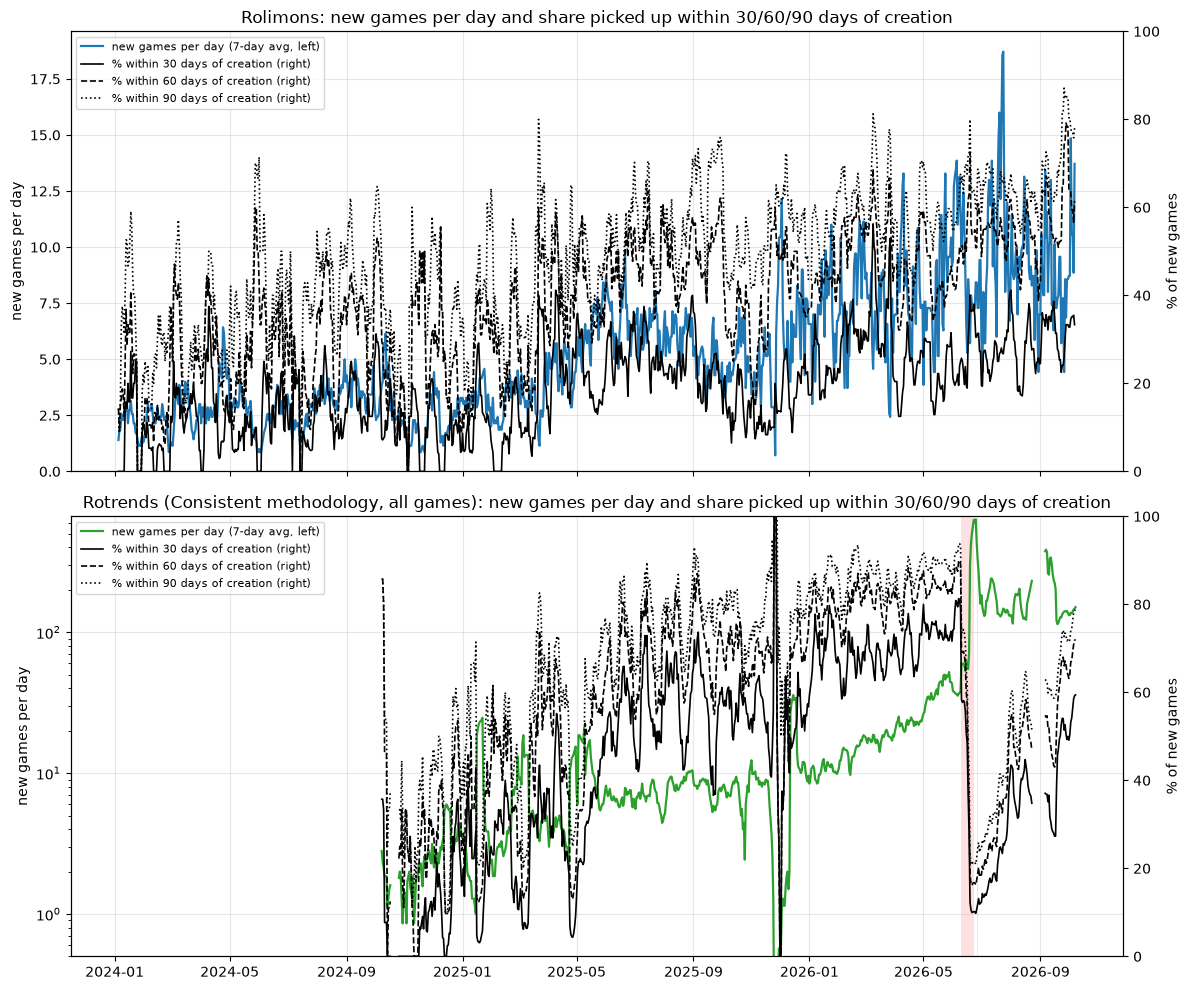

In [11]:
BUCKET_STYLES = {30: "-", 60: "--", 90: ":"}

fig, axes = plt.subplots(2, 1, figsize=(12, 10), sharex=True)

for ax, source, color in [(axes[0], "Rolimons", "tab:blue"), (axes[1], "Rotrends", "tab:green")]:
    d = new_games[source]
    ax.plot(d.index, d["new_games_7d_avg"], lw=1.6, color=color, label="new games per day (7-day avg, left)")
    ax.set_ylabel("new games per day")
    ax.set_ylim(bottom=0)
    if source == "Rotrends":
        ax.set_yscale("log")  # the June 2026 list switch adds ~1,000+ a day
        ax.set_ylim(bottom=0.5)
    ax.grid(alpha=0.3)

    ax2 = ax.twinx()
    for n in LAG_BUCKETS:
        ax2.plot(d.index, d[f"pct_within_{n}d"] * 100, lw=1.2, color="black", ls=BUCKET_STYLES[n],
                 label=f"% within {n} days of creation (right)")
    ax2.set_ylabel("% of new games")
    ax2.set_ylim(0, 100)

    h1, l1 = ax.get_legend_handles_labels()
    h2, l2 = ax2.get_legend_handles_labels()
    ax.legend(h1 + h2, l1 + l2, loc="upper left", fontsize=8)
    title = "Rolimons" if source == "Rolimons" else "Rotrends (Consistent methodology, all games)"
    ax.set_title(f"{title}: new games per day and share picked up within 30/60/90 days of creation")

shade_mistimed(axes[1])
plt.tight_layout()

### Rolimons new games by publication-lag bucket, quarterly

Each quarter's new Rolimons games (first reading that quarter), split by days from Roblox creation to first appearance: **0–30, 31–60, 61–90, over 90**.
- **Share of new games:** the bucket's share of the quarter's new games.
- **Share of CCU:** the bucket's share of the new games' combined CCU, where each game's CCU is its **average daily CCU over its first 30 days in Rolimons** (from its first reading). A fixed 30-day window means a game that arrives at the end of a quarter counts the same as one that arrives at the start. The latest quarter's games may not have 30 days of history yet.

CCU is concentrated in a few games, so a single hit can move a bucket's share by tens of points in a quarter.

In [12]:
LAG_BUCKET_LABELS = ["0-30d", "31-60d", "61-90d", ">90d"]

rolimons_ccu30 = q(f"""
    WITH daily AS (
        SELECT universe_id, runtime :: DATE AS date, AVG(players) AS ccu
        FROM bots.rblx.rolimons_game_universe
        WHERE universe_id IS NOT NULL
        GROUP BY 1, 2
    ),
    firsts AS (
        SELECT universe_id, MIN(date) AS first_seen
        FROM daily
        GROUP BY 1
    )
    SELECT f.universe_id, AVG(d.ccu) AS ccu_first_30d
    FROM firsts f
    JOIN daily d
        ON d.universe_id = f.universe_id
        AND d.date BETWEEN f.first_seen AND DATEADD(day, 29, f.first_seen)
    WHERE f.first_seen >= '{START}'
    GROUP BY 1
""")

rolimons_new = (
    first_seen[first_seen["source"] == "Rolimons"]
    .merge(rolimons_ccu30, on="universe_id", how="left")
    .assign(
        quarter=lambda df: df["date"].dt.to_period("Q"),
        lag_bucket=lambda df: pd.cut(df["lag_days"], [-1, 30, 60, 90, float("inf")], labels=LAG_BUCKET_LABELS),
    )
)

games_by_bucket = pd.crosstab(rolimons_new["quarter"], rolimons_new["lag_bucket"], normalize="index")
ccu_by_bucket = pd.crosstab(
    rolimons_new["quarter"], rolimons_new["lag_bucket"], values=rolimons_new["ccu_first_30d"], aggfunc="sum", normalize="index"
)

lag_bucket_table = pd.concat(
    {
        "new games": rolimons_new.groupby("quarter").size().to_frame("count"),
        "share of new games": games_by_bucket,
        "share of CCU (first 30 days)": ccu_by_bucket,
    },
    axis=1,
)
lag_bucket_table.style.format("{:.0%}").format("{:,.0f}", subset=[("new games", "count")])

## 6. New 1k+ hits (Consistent panel)

Rebuilds the Tableau **NewHitsDashboard** (`rblx-new-hits` subscription, `Datasource=Consistent`, `CCU Threshold=1000`), whose logic is in the Tableau workbook rather than the repo:
- A game's **hit date** is the first date its daily average CCU in `game_trend` (`datasource = 'Consistent'`, `TRUNC(mean_players)`) is 1,000 or more.
- Each game counts **once**, in the week of its hit date (Monday to Sunday, labelled by the Sunday).

The second chart keeps only hits whose **first day in the Consistent panel** was **under 30 days after the game's Roblox creation date**, i.e. genuinely new games rather than established games entering our coverage.
- Creation date is `game_trend.create_date`, with gaps filled from the four-feed creation date in section 5. Hits with no creation date at all are left out of the second chart.
- For the median new hit, the hit date is the **same day it first appears in the panel**. Most new hits are games that join coverage already above 1k, so the first chart jumps when coverage grows: the scan expansions on 2025-04-03 and 2025-07-16, and Rotrends/Rolimons gap-fills. The 30-day filter removes most of that.

The third chart applies the same rule to `game_trend`'s **Combined** datasource: the Consistent panel without the 5k+ cut on the Rotrends gap-fill, so Rotrends gap-fill games count from 1k+ like everything else.

`game_trend` is rebuilt several times a day, and late Rolimons or Rotrends data can add hits to past weeks, so recent weeks are provisional (Tableau's figure for a week can differ from this notebook's if they read different builds). The latest week is partial.

In [13]:
HIT_THRESHOLD = 1000
SEEN_WITHIN_DAYS = 30

new_hits = q(f"""
    WITH created_feeds AS (
        SELECT universe_id, MIN(created) :: DATE AS created
        FROM (
            SELECT universe_id, created_at AS created FROM bots.rblx.game_meta_v3 WHERE universe_id > 0
            UNION ALL
            SELECT universe_id, create_date FROM bots.rblx.game_meta_v2 WHERE universe_id > 0
            UNION ALL
            SELECT game_id, created FROM bots.rblx.rotrend_list
            UNION ALL
            SELECT game_id, created FROM bots.rblx.rotrend_topgames
        )
        WHERE created >= '2006-01-01'
        GROUP BY 1
    ),
    games AS (
        -- As the Tableau NewHitsDashboard: first date TRUNC(mean_players) >= threshold.
        SELECT
            universe_id,
            MIN(IFF(TRUNC(mean_players) >= {HIT_THRESHOLD}, date, NULL)) AS hit_date,
            MIN(date) AS first_seen,
            MIN(IFF(create_date >= '2006-01-01', create_date, NULL)) :: DATE AS create_date
        FROM bots.rblx.game_trend
        WHERE datasource = 'Consistent'
            AND universe_id IS NOT NULL
        GROUP BY 1
        HAVING hit_date IS NOT NULL
    )
    SELECT
        g.universe_id,
        g.hit_date AS date,
        DATEDIFF(day, COALESCE(g.create_date, c.created), g.first_seen) AS seen_lag_days,
        DATEDIFF(day, g.first_seen, g.hit_date) AS days_seen_to_hit
    FROM games g
    LEFT JOIN created_feeds c
        ON c.universe_id = g.universe_id
    WHERE g.hit_date >= '{START}'
""")

# Same rule on the Combined datasource: Consistent without the 5k+ cut on the Rotrends gap-fill.
new_hits_combined = q(f"""
    SELECT universe_id, hit_date AS date
    FROM (
        SELECT universe_id, MIN(IFF(TRUNC(mean_players) >= {HIT_THRESHOLD}, date, NULL)) AS hit_date
        FROM bots.rblx.game_trend
        WHERE datasource = 'Combined'
            AND universe_id IS NOT NULL
        GROUP BY 1
    )
    WHERE hit_date >= '{START}'
""")

for df in (new_hits, new_hits_combined):
    df["week"] = df["date"].dt.to_period("W-SUN").dt.end_time.dt.normalize()
new_hits["seen_within_30d"] = new_hits["seen_lag_days"] < SEEN_WITHIN_DAYS

weekly_hits = new_hits.groupby("week").agg(
    new_hits=("universe_id", "size"),
    new_hits_seen_within_30d=("seen_within_30d", "sum"),
    no_create_date=("seen_lag_days", lambda s: s.isna().sum()),
).join(new_hits_combined.groupby("week").size().rename("new_hits_combined"), how="outer").fillna(0)

new_hits.groupby(new_hits["date"].dt.to_period("Q")).agg(
    new_hits=("universe_id", "size"),
    seen_within_30d=("seen_within_30d", "sum"),
    no_create_date=("seen_lag_days", lambda s: s.isna().sum()),
    median_days_seen_to_hit=("days_seen_to_hit", "median"),
).join(new_hits_combined.groupby(new_hits_combined["date"].dt.to_period("Q")).size().rename("new_hits_combined"))

,new_hits,seen_within_30d,no_create_date,median_days_seen_to_hit,new_hits_combined
date,,,,,
2024Q1,436,81,0,0.0,436
2024Q2,537,79,116,0.0,537
2024Q3,485,77,165,0.0,490
2024Q4,344,56,69,0.0,375
2025Q1,348,58,40,0.0,448
2025Q2,1051,272,349,0.0,1074
2025Q3,1644,520,521,0.0,1677
2025Q4,1080,289,198,0.0,1172
2026Q1,990,424,0,0.0,1158


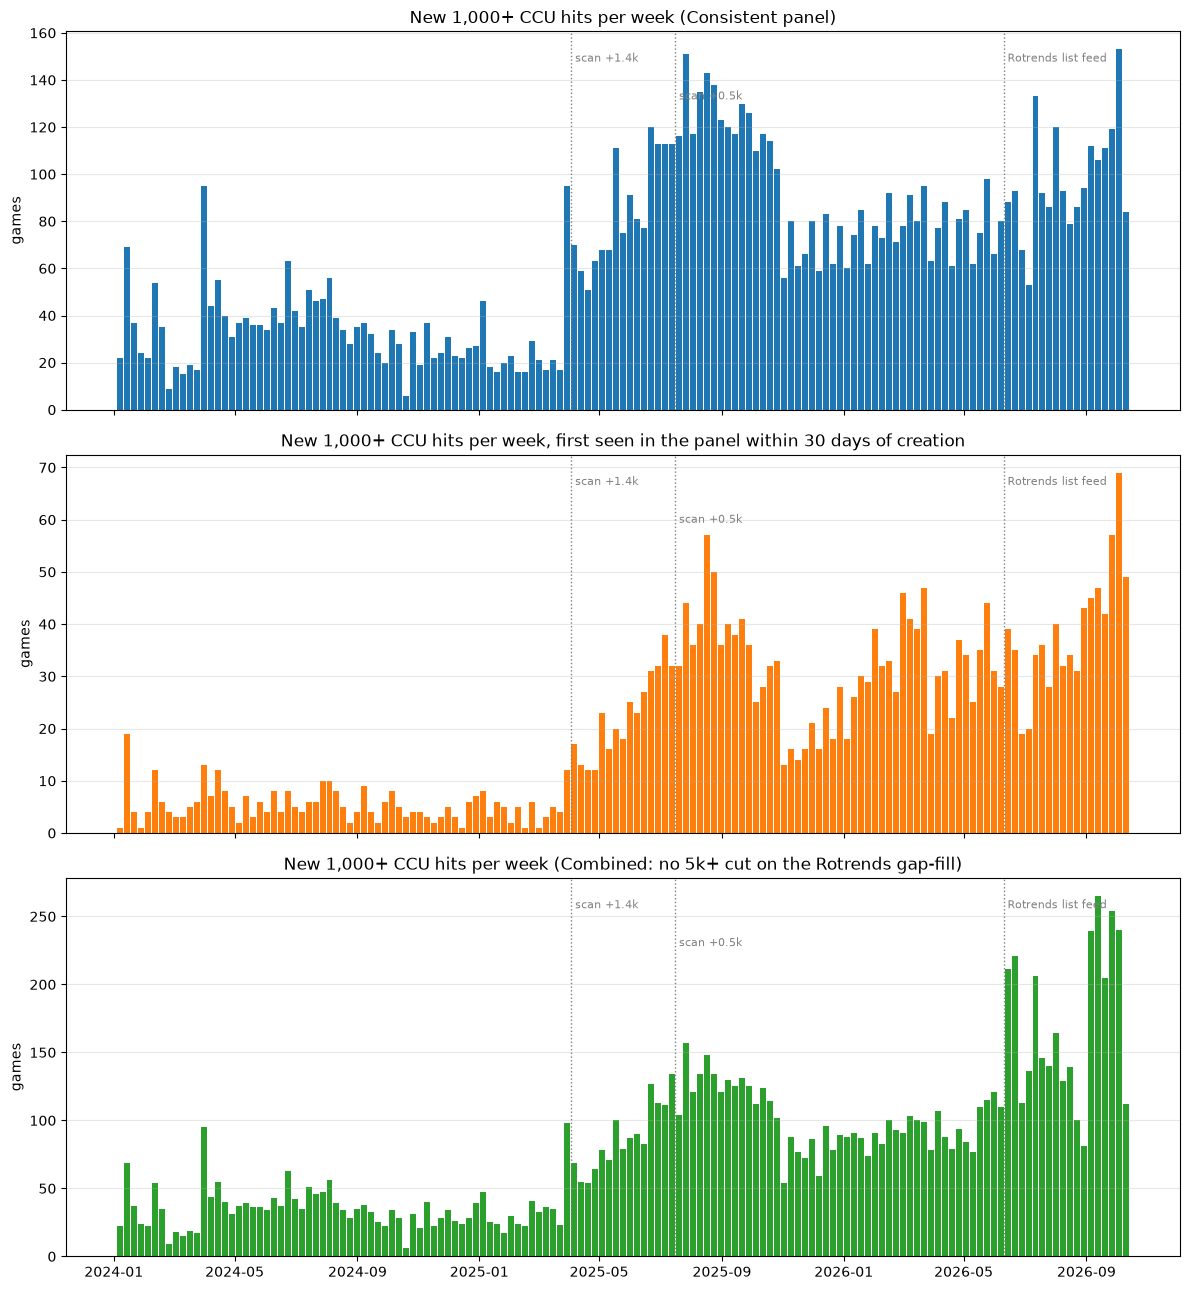

In [14]:
fig, axes = plt.subplots(3, 1, figsize=(12, 13), sharex=True)

for ax, col, title, color in [
    (axes[0], "new_hits", f"New {HIT_THRESHOLD:,}+ CCU hits per week (Consistent panel)", "tab:blue"),
    (axes[1], "new_hits_seen_within_30d",
     f"New {HIT_THRESHOLD:,}+ CCU hits per week, first seen in the panel within {SEEN_WITHIN_DAYS} days of creation", "tab:orange"),
    (axes[2], "new_hits_combined",
     f"New {HIT_THRESHOLD:,}+ CCU hits per week (Combined: no 5k+ cut on the Rotrends gap-fill)", "tab:green"),
]:
    ax.bar(weekly_hits.index, weekly_hits[col], width=6, color=color)
    ax.set_title(title)
    ax.set_ylabel("games")
    ax.grid(alpha=0.3, axis="y")

for ax in axes:
    for d, label, y in [("2025-04-03", "scan +1.4k", 0.92), ("2025-07-16", "scan +0.5k", 0.82), ("2026-06-10", "Rotrends list feed", 0.92)]:
        ax.axvline(pd.Timestamp(d), color="grey", ls=":", lw=1)
        ax.text(pd.Timestamp(d), ax.get_ylim()[1] * y, " " + label, fontsize=8, color="grey")
plt.tight_layout()